In [29]:
import pandas as pd
import requests

# A) Récupération et nettoyage

### 1. Chargement + normalisation des noms de colonnes

In [30]:
dfExistant = pd.read_csv("dpe03existant.csv")

dfExistant.columns = (
    dfExistant.columns
    .str.replace("\ufeff", "")
    .str.strip()
    .str.replace(" ", "_")
)

print(dfExistant.shape)

(10000, 23)


In [31]:
dfExistant.head()

,conso_5_usages_ef,version_dpe,type_generateur_chauffage_principal,type_batiment,periode_construction,type_installation_ecs,type_energie_principale_chauffage,numero_dpe,qualite_isolation_menuiseries,type_energie_principale_ecs,...,isolation_toiture,type_installation_chauffage,nombre_niveau_logement,date_etablissement_dpe,code_postal_ban,surface_habitable_logement,etiquette_dpe,_score,numero_dpe_immeuble_associe,surface_climatisee
0,2439.8,2.6,Chaudière gaz standard après 2015,appartement,2013-2021,collectif,Gaz naturel,2669E0027508W,très bonne,Gaz naturel,...,0.0,collectif,1,2026-01-06,69008,37.5,C,NaN,NaN,NaN
1,8350.3,2.6,Chaudière gaz standard 1991-2000,appartement,1989-2000,individuel,Gaz naturel,2669E0062001N,très bonne,Gaz naturel,...,1.0,individuel,1,2026-01-09,69008,67.5,C,NaN,NaN,NaN
2,4038.3,2.6,NaN,appartement,avant 1948,individuel,Électricité,2669E0010782O,moyenne,Électricité,...,0.0,individuel,1,2026-01-05,69100,21.3,E,NaN,NaN,NaN
3,4054.5,2.6,"Panneau rayonnant électrique NFC, NF** et NF***",appartement,avant 1948,individuel,Électricité,2669E0019280K,bonne,Électricité,...,0.0,individuel,1,2026-01-06,69007,42.0,D,NaN,NaN,NaN
4,4359.7,2.6,Radiateur électrique à accumulation,appartement,1983-1988,individuel,Électricité,2669E0045216Y,moyenne,Électricité,...,0.0,individuel,1,2026-01-08,69006,55.0,C,NaN,NaN,NaN


### 2. Contrôle de l'échantillon (biais des premières lignes de l'API)

In [32]:
print(dfExistant["code_postal_ban"].value_counts())
print(dfExistant["version_dpe"].value_counts().sort_index())
print(dfExistant["type_batiment"].value_counts())

dfExistant["date_etablissement_dpe"] = pd.to_datetime(dfExistant["date_etablissement_dpe"])
print(dfExistant["date_etablissement_dpe"].agg(["min", "max"]))

code_postal_ban
69100    1546
69007    1309
69003    1183
69008     887
69009     790
69006     769
69002     532
69001     484
69005     473
69300     447
69004     346
69700     293
69600     254
69500     250
69150     205
69140     119
69130     113
Name: count, dtype: int64
version_dpe
2.1    6303
2.2      93
2.3     236
2.4     320
2.5      60
2.6    2988
Name: count, dtype: int64
type_batiment
appartement    9627
maison          373
Name: count, dtype: int64
min   2021-08-04
max   2026-01-30
Name: date_etablissement_dpe, dtype: datetime64[us]


### 3. Filtre du périmètre (version et immeubles déjà filtrés par l'API, gardés par sécurité)

In [33]:
dfFiltre = dfExistant[
    (dfExistant["type_batiment"] != "immeuble")
    & (dfExistant["methode_application_dpe"] != "dpe appartement généré à partir des données DPE immeuble")
    & (dfExistant["version_dpe"] >= 2.1)
].copy()

print(dfFiltre.shape)

(8779, 23)


### 4. Sélection des variables

In [34]:
ls_columns = [
    # cibles
    'etiquette_dpe',
    'conso_5_usages_ef',
    # variables du formulaire
    'code_postal_ban',
    'type_batiment',
    'surface_habitable_logement',
    'periode_construction',
    'nombre_niveau_logement',
    'type_energie_principale_chauffage',
    'type_generateur_chauffage_principal',
    'type_installation_chauffage',
    'type_energie_principale_ecs',
    'type_installation_ecs',
    'isolation_toiture',
    'qualite_isolation_menuiseries',
    'surface_climatisee',
    'logement_traversant',
    'type_generateur_n1_installation_n1',
]

# Vérification : doit renvoyer []
print([c for c in ls_columns if c not in dfFiltre.columns])

dfClean = dfFiltre[ls_columns].copy()

# Climatisation (0/1) à la place de la surface climatisée
dfClean["climatisation"] = (dfClean["surface_climatisee"].fillna(0) > 0).astype(int)
dfClean = dfClean.drop(columns=["surface_climatisee"])

[]


### 5. Diagnostic

In [35]:
missing_rate = dfClean.isna().mean().sort_values(ascending=False) * 100
print("Taux de valeurs manquantes (%) par colonne :")
print(missing_rate)

# Répartition des cibles
print(dfClean["etiquette_dpe"].value_counts().reindex(["A", "B", "C", "D", "E", "F", "G"]))
print(dfClean["conso_5_usages_ef"].describe())

# Modalités des variables qualitatives
print(dfClean.select_dtypes(exclude="number").nunique().sort_values(ascending=False))
print(dfClean["type_generateur_chauffage_principal"].value_counts())

Taux de valeurs manquantes (%) par colonne :
type_generateur_chauffage_principal    65.383301
isolation_toiture                      18.999886
logement_traversant                    18.589817
type_installation_chauffage             4.248775
type_installation_ecs                   4.248775
etiquette_dpe                           0.000000
conso_5_usages_ef                       0.000000
type_batiment                           0.000000
code_postal_ban                         0.000000
type_energie_principale_chauffage       0.000000
nombre_niveau_logement                  0.000000
periode_construction                    0.000000
surface_habitable_logement              0.000000
type_energie_principale_ecs             0.000000
qualite_isolation_menuiseries           0.000000
type_generateur_n1_installation_n1      0.000000
climatisation                           0.000000
dtype: float64
etiquette_dpe
A      19
B     214
C    3149
D    3029
E    1515
F     583
G     270
Name: count, dtype: int

In [36]:
cols_suspectes = ["type_generateur_chauffage_principal", "isolation_toiture", "logement_traversant"]

for col in cols_suspectes:
    print(f"\n{col} - % de NaN par version")
    print((dfFiltre.groupby("version_dpe")[col].apply(lambda s: s.isna().mean() * 100)).round(1))


type_generateur_chauffage_principal - % de NaN par version
version_dpe
2.1    94.0
2.2     1.1
2.3     1.5
2.4     0.0
2.5    10.0
2.6     8.3
Name: type_generateur_chauffage_principal, dtype: float64

isolation_toiture - % de NaN par version
version_dpe
2.1    28.4
2.2     0.0
2.3     0.0
2.4     0.0
2.5     0.0
2.6     0.1
Name: isolation_toiture, dtype: float64

logement_traversant - % de NaN par version
version_dpe
2.1    27.8
2.2     0.0
2.3     0.0
2.4     0.0
2.5     0.0
2.6     0.0
Name: logement_traversant, dtype: float64


In [37]:
generateur = dfFiltre["type_generateur_chauffage_principal"].fillna(dfFiltre["type_generateur_n1_installation_n1"])
print("NaN avant :", dfFiltre["type_generateur_chauffage_principal"].isna().mean() * 100)
print("NaN après :", generateur.isna().mean() * 100)

NaN avant : 65.38330105934617
NaN après : 0.0


In [38]:
dfClean["conso_m2"] = dfClean["conso_5_usages_ef"] / dfClean["surface_habitable_logement"]
dfClean.sort_values("conso_m2", ascending=False).head(10)

,etiquette_dpe,conso_5_usages_ef,code_postal_ban,type_batiment,surface_habitable_logement,periode_construction,nombre_niveau_logement,type_energie_principale_chauffage,type_generateur_chauffage_principal,type_installation_chauffage,type_energie_principale_ecs,type_installation_ecs,isolation_toiture,qualite_isolation_menuiseries,logement_traversant,type_generateur_n1_installation_n1,climatisation,conso_m2
5711,G,26923.8,69500,appartement,27.1,1948-1974,1,Gaz naturel,NaN,collectif,Gaz naturel,collectif,0.0,moyenne,0.0,Chaudière gaz classique avant 1981,0,993.498155
9911,G,9435.9,69130,appartement,10.9,avant 1948,2,Gaz naturel,NaN,collectif,Non affecté,individuel,0.0,moyenne,1.0,Chaudière gaz classique avant 1981,0,865.678899
6553,G,10018.6,69130,appartement,13.1,avant 1948,2,Gaz naturel,NaN,collectif,Non affecté,individuel,0.0,moyenne,1.0,Chaudière gaz classique avant 1981,0,764.778626
5539,G,28293.6,69006,appartement,43.4,avant 1948,1,Fioul domestique,NaN,individuel,Électricité,individuel,0.0,insuffisante,1.0,Poêle fioul ou GPL ou charbon,0,651.926267
2232,G,5255.7,69004,appartement,8.1,avant 1948,1,Électricité,"Convecteur électrique NFC, NF** et NF***",individuel,Électricité,individuel,0.0,insuffisante,0.0,"Convecteur électrique NFC, NF** et NF***",0,648.851852
4015,G,15539.9,69005,appartement,24.2,1948-1974,1,Gaz naturel,NaN,collectif,Gaz naturel,collectif,0.0,insuffisante,0.0,Chaudière gaz classique avant 1981,0,642.144628
4118,G,30547.0,69009,appartement,47.8,avant 1948,1,Gaz naturel,NaN,individuel,Gaz naturel,individuel,NaN,moyenne,NaN,Chaudière gaz standard 2001-2015,0,639.058577
9436,G,29630.1,69500,appartement,47.6,1948-1974,1,Gaz naturel,NaN,individuel,Gaz naturel,collectif,0.0,insuffisante,0.0,Chaudière gaz standard 1991-2000,0,622.481092
7895,G,24912.5,69005,appartement,42.0,avant 1948,1,Gaz naturel,NaN,individuel,Gaz naturel,individuel,0.0,moyenne,0.0,Chaudière gaz basse température après 2015,0,593.154762
7213,G,5437.3,69006,appartement,9.2,1948-1974,1,Fioul domestique,NaN,collectif,Fioul domestique,collectif,0.0,insuffisante,0.0,Chaudière fioul classique avant 1970,0,591.010870


### 6. Variable générateur : principal, complété par l'installation n1 pour les versions DPE 2.1

In [39]:
dfClean["generateur"] = dfClean["type_generateur_chauffage_principal"].fillna(
    dfClean["type_generateur_n1_installation_n1"]
)
dfClean = dfClean.drop(columns=["type_generateur_chauffage_principal",
                                "type_generateur_n1_installation_n1",
                                "conso_m2"], errors="ignore")

### 7. Regroupement des générateurs en familles

L'ordre des tests compte : "PAC hybride" doit tomber dans PAC, "chaudière électrique" avant le cas électrique générique

In [40]:
def famille_generateur(libelle):
    s = str(libelle).lower()

    if "pac " in s or s.startswith("pac") or "pompe à chaleur" in s:
        return "PAC"
    if "réseau de chaleur" in s:
        return "Réseau de chaleur"
    if "chaudière" in s and "électrique" in s:
        return "Électrique direct"
    if "chaudière" in s and ("gaz" in s or "gpl" in s) and "condensation" in s:
        return "Chaudière gaz condensation"
    if ("chaudière" in s and ("gaz" in s or "gpl" in s)) or "combustion gaz" in s:
        return "Chaudière gaz non condensation"
    if "chaudière" in s and "fioul" in s:
        return "Chaudière fioul"
    if ("bois" in s or "granulés" in s or "bûche" in s or "plaquette" in s
            or "foyer fermé" in s or "insert" in s or "cuisinière" in s):
        return "Bois"
    if "accumulation" in s:
        return "Électrique accumulation"
    if "électrique" in s or "effet joule" in s or "convecteur" in s:
        return "Électrique direct"
    if "poêle" in s or "radiateur à gaz" in s:
        return "Poêle / radiateur autonome"
    return "Autre"

dfClean["generateur"] = dfClean["generateur"].apply(famille_generateur)
print(dfClean["generateur"].value_counts())

generateur
Électrique direct                 2943
Chaudière gaz non condensation    2342
Chaudière gaz condensation        1446
Électrique accumulation            928
Réseau de chaleur                  590
PAC                                235
Poêle / radiateur autonome         181
Chaudière fioul                     82
Bois                                32
Name: count, dtype: int64


In [41]:
# Contrôle : quels libellés tombent dans "Autre" ? (à affiner si besoin)
print(dfFiltre.loc[dfClean.index[dfClean["generateur"] == "Autre"], "type_generateur_n1_installation_n1"].value_counts())

Series([], Name: count, dtype: int64)


### 8. Test des générateurs tombant dans la catégorie "Autre"

In [42]:
codes_postaux = [
    "69001", "69002", "69003", "69004", "69005", "69006", "69007", "69008", "69009",
    "69100", "69500", "69300", "69130", "69150", "69600", "69140", "69700",
]

In [43]:
URL_AGG = "https://data.ademe.fr/data-fair/api/v1/datasets/meg-83tjwtg8dyz4vv7h1dqe/values_agg"

params = {
    "field": "type_generateur_n1_installation_n1",
    "qs": (
        f"code_postal_ban:({' OR '.join(codes_postaux)})"
        " AND version_dpe:[2.1 TO *]"
        " AND NOT type_batiment:immeuble"
    ),
    "agg_size": 200,  # nombre max de modalités renvoyées
}

r = requests.get(URL_AGG, params=params)
r.raise_for_status()

modalites = pd.DataFrame(
    [(a["value"], a["total"]) for a in r.json()["aggs"]],
    columns=["libelle", "effectif"],
)
modalites["famille"] = modalites["libelle"].apply(famille_generateur)

# Ce qui tombe dans "Autre" sur TOUTE la Métropole
print(modalites[modalites["famille"] == "Autre"])

# Effectif par famille sur toute la Métropole
print(modalites.groupby("famille")["effectif"].sum().sort_values(ascending=False))

                                               libelle  effectif famille
64      générateur à air chaud à combustion avant 2006        38   Autre
91   générateur à air chaud à combustion standard a...        10   Autre
107                       Chaudière charbon avant 1978         3   Autre
111                   autre système à combustion fioul         3   Autre
112  générateur à air chaud à combustion à condensa...         3   Autre
116                        Chaudière charbon 1978-1994         1   Autre
123  autre système à combustion autres energies fos...         1   Autre
famille
Électrique direct                 77734
Chaudière gaz non condensation    68579
Chaudière gaz condensation        64879
Réseau de chaleur                 56683
Électrique accumulation           26956
PAC                                5351
Poêle / radiateur autonome         3867
Chaudière fioul                    1781
Bois                               1346
Autre                                59
Name: ef

In [44]:
print(modalites[modalites["famille"] == "Autre"].sort_values("effectif", ascending=False))

                                               libelle  effectif famille
64      générateur à air chaud à combustion avant 2006        38   Autre
91   générateur à air chaud à combustion standard a...        10   Autre
107                       Chaudière charbon avant 1978         3   Autre
111                   autre système à combustion fioul         3   Autre
112  générateur à air chaud à combustion à condensa...         3   Autre
116                        Chaudière charbon 1978-1994         1   Autre
123  autre système à combustion autres energies fos...         1   Autre


In [45]:
part_autre = (dfClean["generateur"] == "Autre").mean() * 100
print(f"Part de 'Autre' : {part_autre:.1f} %")
if part_autre > 2:
    print("ATTENTION : Beaucoup de générateurs non classés : vérifier famille_generateur()")

Part de 'Autre' : 0.0 %


### 9. Derniers ajustements

In [46]:
# Lignes avec NaN résiduels (isolation_toiture, logement_traversant, type_installation_*)
print("Avant :", dfClean.shape)
dfClean = dfClean.dropna()
print("Après :", dfClean.shape)

# Fusion des classes A et B (A trop rare)
dfClean["etiquette_dpe"] = dfClean["etiquette_dpe"].replace({"A": "A-B", "B": "A-B"})

# Code postal en catégorie (sinon traité comme une grandeur continue)
dfClean["code_postal_ban"] = dfClean["code_postal_ban"].astype(str)

print(dfClean["etiquette_dpe"].value_counts())
dfClean.info()

Avant : (8779, 16)
Après : (6810, 16)
etiquette_dpe
C      2519
D      2341
E      1141
F       436
G       191
A-B     182
Name: count, dtype: int64
<class 'pandas.DataFrame'>
Index: 6810 entries, 0 to 9999
Data columns (total 16 columns):
 #   Column                             Non-Null Count  Dtype  
---  ------                             --------------  -----  
 0   etiquette_dpe                      6810 non-null   str    
 1   conso_5_usages_ef                  6810 non-null   float64
 2   code_postal_ban                    6810 non-null   str    
 3   type_batiment                      6810 non-null   str    
 4   surface_habitable_logement         6810 non-null   float64
 5   periode_construction               6810 non-null   str    
 6   nombre_niveau_logement             6810 non-null   int64  
 7   type_energie_principale_chauffage  6810 non-null   str    
 8   type_installation_chauffage        6810 non-null   str    
 9   type_energie_principale_ecs        6810 non-null  

### 10. Encodage ordinal + types

In [47]:
print(dfClean["periode_construction"].unique())  # vérifier les libellés avant le mapping

ordre_periode = {
    "avant 1948": 0, "1948-1974": 1, "1975-1977": 2, "1978-1982": 3, "1983-1988": 4,
    "1989-2000": 5, "2001-2005": 6, "2006-2012": 7, "2013-2021": 8, "après 2021": 9,
}
ordre_menuiseries = {"insuffisante": 0, "moyenne": 1, "bonne": 2, "très bonne": 3}

dfClean["periode_construction"] = dfClean["periode_construction"].map(ordre_periode)
dfClean["qualite_isolation_menuiseries"] = dfClean["qualite_isolation_menuiseries"].map(ordre_menuiseries)

dfClean[["isolation_toiture", "logement_traversant"]] = dfClean[["isolation_toiture", "logement_traversant"]].astype(int)

# Contrôle : un libellé absent du mapping donnerait un NaN
print(dfClean[["periode_construction", "qualite_isolation_menuiseries"]].isna().sum())

<StringArray>
[ '2013-2021',  '1989-2000', 'avant 1948',  '1983-1988',  '2006-2012',
  '1948-1974', 'après 2021',  '2001-2005',  '1978-1982',  '1975-1977']
Length: 10, dtype: str
periode_construction             0
qualite_isolation_menuiseries    0
dtype: int64


# B) Classification

### 1. Séparation X / Y

In [48]:
cibles = ["etiquette_dpe", "conso_5_usages_ef"]

Y = dfClean["etiquette_dpe"]
X = dfClean.drop(columns=cibles)

# Binarisation des variables catégorielles
X = pd.get_dummies(X, drop_first=True)
print(X.shape)

(6810, 49)


### 2. Échantillonnage train / test

In [49]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, Y, test_size=0.30, random_state=42, stratify=Y
)

print("Taille X_train :", len(X_train))
print("Taille X_test  :", len(X_test))
print("\nDistribution de y_train :")
print(y_train.value_counts(normalize=True).round(3))

Taille X_train : 4767
Taille X_test  : 2043

Distribution de y_train :
etiquette_dpe
C      0.370
D      0.344
E      0.168
F      0.064
G      0.028
A-B    0.027
Name: proportion, dtype: float64


### 3. Arbre de décision avec GridSearch

In [50]:
import numpy as np
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import GridSearchCV

parameters = {
    'max_depth': np.arange(3, 16, 2),
    'min_samples_leaf': [5, 10, 25, 50, 100],
    'min_samples_split': [10, 50, 100, 200],
}

grid_arbre = GridSearchCV(
    DecisionTreeClassifier(random_state=42),
    parameters,
    scoring="f1_macro",
    cv=5,
    n_jobs=-1,
)
grid_arbre.fit(X_train, y_train)

best_arbre = grid_arbre.best_estimator_
print("Meilleurs paramètres :", grid_arbre.best_params_)
print("F1 macro (CV) :", round(grid_arbre.best_score_, 3))

Meilleurs paramètres : {'max_depth': np.int64(13), 'min_samples_leaf': 5, 'min_samples_split': 10}
F1 macro (CV) : 0.335


### 4.Évaluation sur le test

In [51]:
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

y_pred_arbre = best_arbre.predict(X_test)

print(classification_report(y_test, y_pred_arbre))

# Matrice de confusion ordonnée
ordre_dpe = ["A-B", "C", "D", "E", "F", "G"]
mc = pd.DataFrame(
    confusion_matrix(y_test, y_pred_arbre, labels=ordre_dpe),
    columns=[f"pred_{e}" for e in ordre_dpe],
    index=[f"obs_{e}" for e in ordre_dpe],
)
mc["Total"] = mc.sum(axis=1)
mc.loc["Total"] = mc.sum(axis=0)
mc

              precision    recall  f1-score   support

         A-B       0.48      0.40      0.44        55
           C       0.65      0.68      0.66       756
           D       0.45      0.54      0.49       702
           E       0.29      0.27      0.28       342
           F       0.21      0.07      0.10       131
           G       0.00      0.00      0.00        57

    accuracy                           0.50      2043
   macro avg       0.35      0.33      0.33      2043
weighted avg       0.47      0.50      0.48      2043



,pred_A-B,pred_C,pred_D,pred_E,pred_F,pred_G,Total
obs_A-B,22,30,3,0,0,0,55
obs_C,18,511,190,33,4,0,756
obs_D,4,168,378,136,13,3,702
obs_E,2,56,176,94,14,0,342
obs_F,0,10,71,41,9,0,131
obs_G,0,7,24,23,3,0,57
Total,46,782,842,327,43,3,2043


In [52]:
# Accuracy à +/-1 classe (étiquette ordinale)
rang = {e: i for i, e in enumerate(ordre_dpe)}
ecart = np.abs(y_test.map(rang).values - pd.Series(y_pred_arbre).map(rang).values)
print("Accuracy stricte :", round(accuracy_score(y_test, y_pred_arbre), 3))
print("Accuracy à +/-1 classe :", round((ecart <= 1).mean(), 3))

Accuracy stricte : 0.496
Accuracy à +/-1 classe : 0.876


### 5. Interprétation

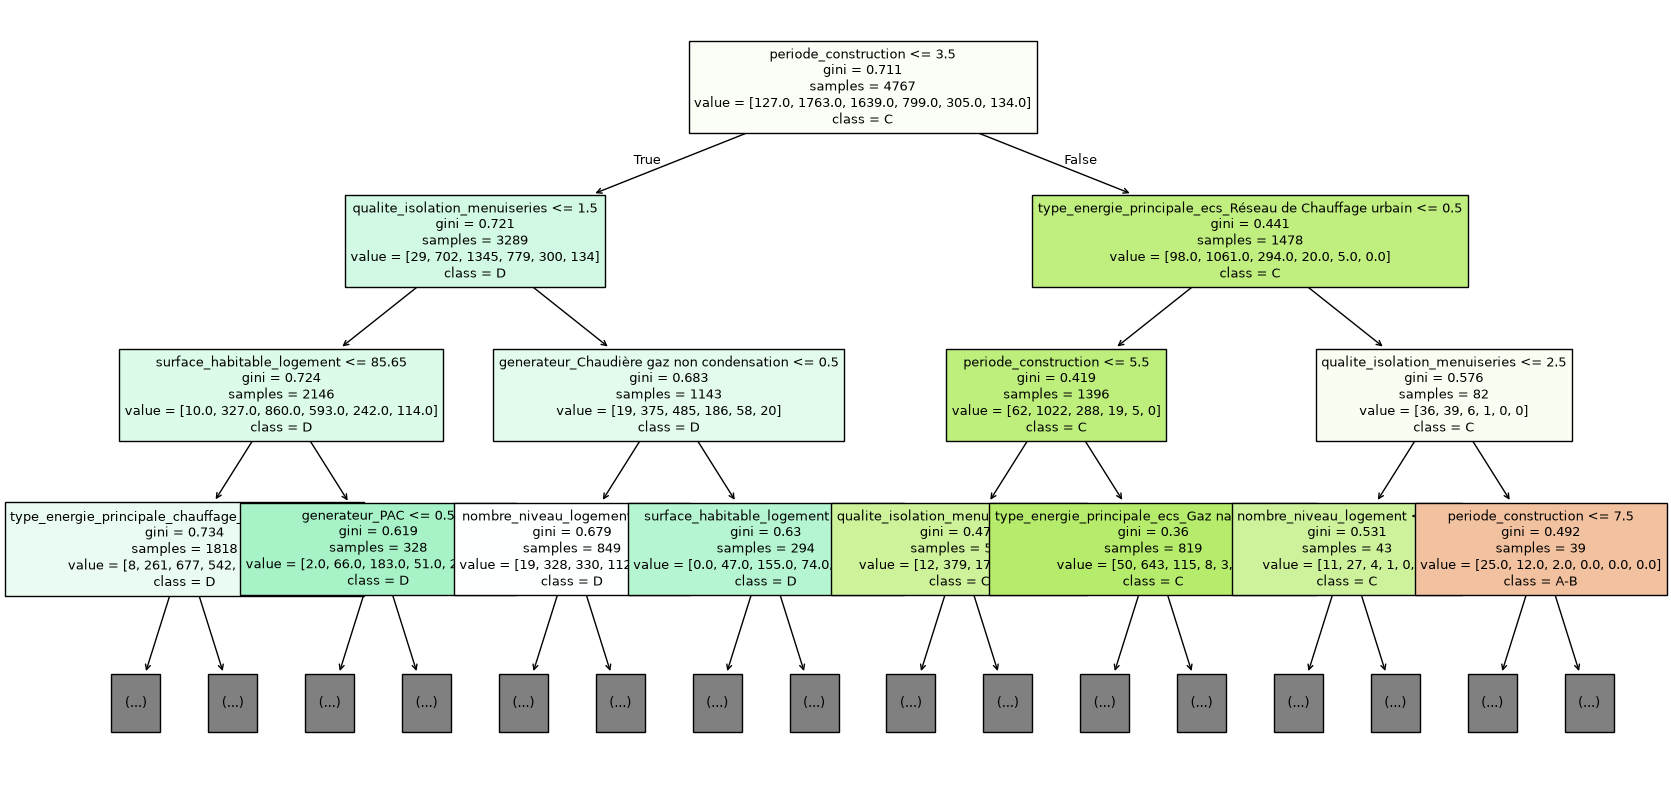

,Feature,Importance
1,periode_construction,0.329116
0,surface_habitable_logement,0.270578
4,qualite_isolation_menuiseries,0.070785
3,isolation_toiture,0.028718
2,nombre_niveau_logement,0.026543
5,logement_traversant,0.024273
12,code_postal_ban_69007,0.022761
39,type_installation_ecs_individuel,0.021599
43,generateur_Chaudière gaz non condensation,0.018653
37,type_energie_principale_ecs_Réseau de Chauffag...,0.015550


In [53]:
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree

# Les 3 premiers niveaux suffisent pour l'interprétation
plt.figure(figsize=(20, 10))
plot_tree(best_arbre, feature_names=X.columns, class_names=best_arbre.classes_,
          filled=True, fontsize=9, max_depth=3)
plt.show()

importances = pd.DataFrame({
    'Feature': X_train.columns,
    'Importance': best_arbre.feature_importances_
}).sort_values(by='Importance', ascending=False)
importances.head(15)

### 6. Forêt aléatoire

In [54]:
from sklearn.ensemble import RandomForestClassifier

param_grid = {
    'n_estimators': [100, 300],
    'max_depth': [10, 15, None],
    'min_samples_leaf': [1, 5, 10],
    'class_weight': [None, 'balanced'],
}

grid_rf = GridSearchCV(
    RandomForestClassifier(random_state=42, n_jobs=-1),
    param_grid,
    scoring="f1_macro",
    cv=5,
)
grid_rf.fit(X_train, y_train)

best_rf = grid_rf.best_estimator_
print("Meilleurs paramètres :", grid_rf.best_params_)
print("F1 macro (CV) :", round(grid_rf.best_score_, 3))

y_pred_rf = best_rf.predict(X_test)
print(classification_report(y_test, y_pred_rf))

ecart_rf = np.abs(y_test.map(rang).values - pd.Series(y_pred_rf).map(rang).values)
print("Accuracy à ±1 classe :", round((ecart_rf <= 1).mean(), 3))

Meilleurs paramètres : {'class_weight': 'balanced', 'max_depth': 10, 'min_samples_leaf': 1, 'n_estimators': 300}
F1 macro (CV) : 0.383
              precision    recall  f1-score   support

         A-B       0.41      0.56      0.47        55
           C       0.74      0.70      0.72       756
           D       0.59      0.32      0.42       702
           E       0.34      0.32      0.33       342
           F       0.14      0.21      0.17       131
           G       0.09      0.58      0.16        57

    accuracy                           0.47      2043
   macro avg       0.38      0.45      0.38      2043
weighted avg       0.56      0.47      0.49      2043

Accuracy à ±1 classe : 0.778


# C) Prétraitement Régression

### 1. Séparation X / Y (régression)

In [55]:
cibles = ["etiquette_dpe", "conso_5_usages_ef"]

Yr = dfClean["conso_5_usages_ef"]
Xr = dfClean.drop(columns=cibles)

# Binarisation des variables catégorielles
Xr = pd.get_dummies(Xr, drop_first=True)
print(Xr.shape)

(6810, 49)


### 2. Analyse de la variable cible

In [57]:
import plotly.express as px

fig = px.box(dfClean, y="conso_5_usages_ef",
             title="Distribution de la consommation 5 usages (kWh EF/an)")
fig.show()

print(Yr.describe(percentiles=[0.01, 0.5, 0.99]))

count     6810.000000
mean      8933.414493
std       6588.271024
min        164.400000
1%        1587.400000
50%       7092.000000
99%      30735.214000
max      71968.100000
Name: conso_5_usages_ef, dtype: float64


### 3. Échantillonnage train / test

In [58]:
from sklearn.model_selection import train_test_split

Xr_train, Xr_test, yr_train, yr_test = train_test_split(
    Xr, Yr, test_size=0.30, random_state=42
)

print("Taille Xr_train :", len(Xr_train))
print("Taille Xr_test  :", len(Xr_test))

Taille Xr_train : 4767
Taille Xr_test  : 2043


### 4. Gestion des valeurs extrêmes

In [59]:
cols_continues = ["surface_habitable_logement", "nombre_niveau_logement"]

for c in cols_continues:
    q_low, q_high = Xr_train[c].quantile([0.01, 0.99])
    Xr_train[c] = Xr_train[c].clip(q_low, q_high)
    Xr_test[c] = Xr_test[c].clip(q_low, q_high)

# Cible : clipping sur le train uniquement (le test garde ses vraies valeurs)
y_low, y_high = yr_train.quantile([0.01, 0.99])
yr_train = yr_train.clip(y_low, y_high)

print("Bornes de la cible :", round(y_low, 1), "-", round(y_high, 1))

Bornes de la cible : 1568.4 - 32013.1


### 5. Fonction d'évaluation commune aux modèles de régression

In [60]:
import numpy as np
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

def evaluer_regression(nom, y_obs, y_pred):
    rmse = np.sqrt(mean_squared_error(y_obs, y_pred))
    mae = mean_absolute_error(y_obs, y_pred)
    r2 = r2_score(y_obs, y_pred)
    print(f"{nom} - RMSE : {rmse:.1f} | MAE : {mae:.1f} | R² : {r2:.3f}")

    fig = px.scatter(x=y_obs, y=y_pred, opacity=0.5,
                     labels={"x": "Valeurs observées", "y": "Valeurs prédites"},
                     title=f"{nom} : Observé vs Prédit")
    borne = max(np.max(y_obs), np.max(y_pred))
    fig.add_scatter(x=[0, borne], y=[0, borne], mode="lines", name="Prédiction parfaite",
                    line=dict(color="red", dash="dash"))
    fig.show()

    return {"Modèle": nom, "RMSE": rmse, "MAE": mae, "R²": r2}

# D) Régression Lasso

### 1. Standardisation

In [61]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
Xr_train_scaled = scaler.fit_transform(Xr_train)
Xr_test_scaled = scaler.transform(Xr_test)

### 2. Chemin de régularisation

In [62]:
import plotly.graph_objects as go
from sklearn.linear_model import Lasso

alphas = np.logspace(-2, 4, 60)
coefs = []

for alpha in alphas:
    lasso_model = Lasso(alpha=alpha, max_iter=10000)
    lasso_model.fit(Xr_train_scaled, yr_train)
    coefs.append(lasso_model.coef_)

coefs = np.array(coefs)

fig = go.Figure()
for i, feature in enumerate(Xr_train.columns):
    fig.add_trace(go.Scatter(x=alphas, y=coefs[:, i], mode="lines", name=feature))

fig.update_layout(title="Lasso : coefficients selon la régularisation",
                  xaxis_title="alpha", yaxis_title="coefficient",
                  width=1100, height=650, template="plotly_white")
fig.update_xaxes(type="log", autorange="reversed")
fig.show()

C:\Users\User\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:716: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 7.482e+09, tolerance: 1.859e+07
  model = cd_fast.enet_coordinate_descent(
C:\Users\User\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:716: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 5.640e+09, tolerance: 1.859e+07
  model = cd_fast.enet_coordinate_descent(
C:\Users\User\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:716: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale 

### 3. Choix d'alpha par GridSearch

In [63]:
from sklearn.model_selection import GridSearchCV

grid_lasso = GridSearchCV(
    Lasso(max_iter=10000),
    {"alpha": np.logspace(-2, 4, 30)},
    scoring="neg_root_mean_squared_error",
    cv=5,
    n_jobs=-1,
)
grid_lasso.fit(Xr_train_scaled, yr_train)

best_lasso = grid_lasso.best_estimator_
print("Meilleur alpha :", round(grid_lasso.best_params_["alpha"], 3))
print("RMSE (CV) :", round(-grid_lasso.best_score_, 1))

Meilleur alpha : 3.039
RMSE (CV) : 3352.7


### 4. Évaluation sur le test

In [65]:
y_pred_lasso = best_lasso.predict(Xr_test_scaled)
res_lasso = evaluer_regression("Lasso", yr_test, y_pred_lasso)

Lasso - RMSE : 3480.6 | MAE : 2478.0 | R² : 0.695


### 5. Interprétation des coefficients

In [66]:
coef_lasso = pd.DataFrame({
    "Variable": Xr_train.columns,
    "Coefficient": best_lasso.coef_,
}).sort_values(by="Coefficient", key=abs, ascending=False)

print("Variables éliminées par le Lasso :", (coef_lasso["Coefficient"] == 0).sum(), "/", len(coef_lasso))
coef_lasso[coef_lasso["Coefficient"] != 0]

Variables éliminées par le Lasso : 7 / 49


,Variable,Coefficient
0,surface_habitable_logement,3451.336357
1,periode_construction,-1807.571510
48,generateur_Électrique direct,-1396.788748
26,type_energie_principale_chauffage_Fioul domest...,1128.486292
47,generateur_Électrique accumulation,-1024.081165
43,generateur_Chaudière gaz non condensation,971.941189
4,qualite_isolation_menuiseries,-861.983791
41,generateur_Chaudière fioul,-817.222331
39,type_installation_ecs_individuel,-742.359344
44,generateur_PAC,-660.452225


# E) Forêt aléatoire de régression

### 1. Forêt aléatoire avec GridSearch

In [67]:
from sklearn.ensemble import RandomForestRegressor

param_grid = {
    "n_estimators": [100, 300],
    "max_depth": [10, 15, None],
    "min_samples_leaf": [1, 5, 10],
}

grid_rf_reg = GridSearchCV(
    RandomForestRegressor(random_state=42, n_jobs=-1),
    param_grid,
    scoring="neg_root_mean_squared_error",
    cv=5,
)
grid_rf_reg.fit(Xr_train, yr_train)

best_rf_reg = grid_rf_reg.best_estimator_
print("Meilleurs paramètres :", grid_rf_reg.best_params_)
print("RMSE (CV) :", round(-grid_rf_reg.best_score_, 1))

Meilleurs paramètres : {'max_depth': 15, 'min_samples_leaf': 5, 'n_estimators': 300}
RMSE (CV) : 3055.6


### 2. Évaluation sur le test

In [68]:
y_pred_rf_reg = best_rf_reg.predict(Xr_test)
res_rf_reg = evaluer_regression("Random Forest", yr_test, y_pred_rf_reg)

Random Forest - RMSE : 3156.4 | MAE : 2056.8 | R² : 0.750


### 3. Importance des variables

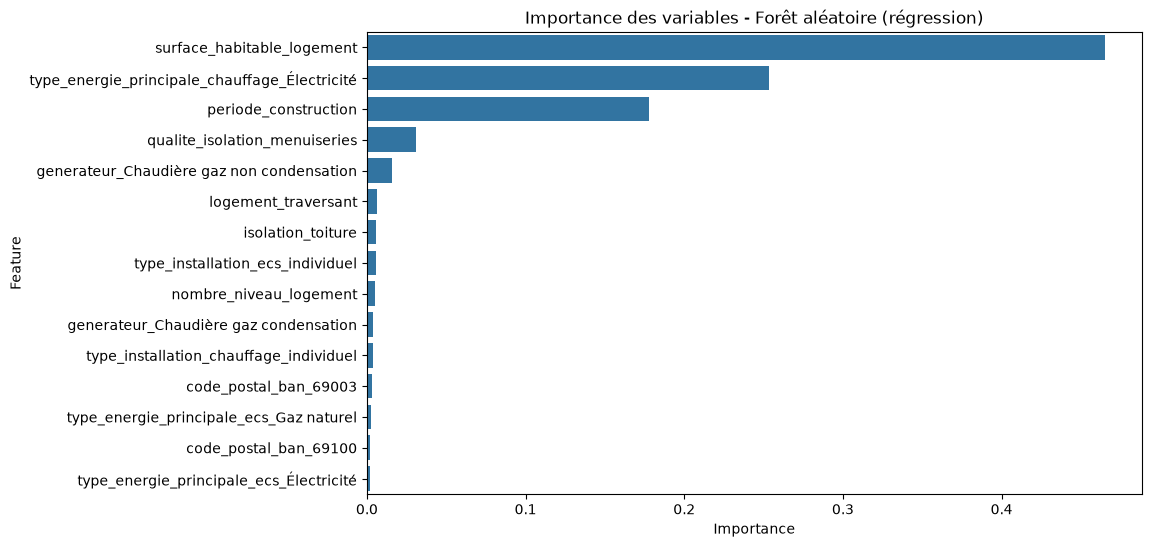

In [69]:
import seaborn as sns
import matplotlib.pyplot as plt

importance_reg = pd.DataFrame({
    "Feature": Xr_train.columns,
    "Importance": best_rf_reg.feature_importances_,
}).sort_values(by="Importance", ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(x="Importance", y="Feature", data=importance_reg.head(15))
plt.title("Importance des variables - Forêt aléatoire (régression)")
plt.show()

# F) Tableau comparatif

In [70]:
import numpy as np
import pandas as pd
from sklearn.metrics import (accuracy_score, f1_score,
                             mean_squared_error, mean_absolute_error, r2_score)

# Modèles à comparer : nom affiché -> (nom de la variable, X de test à utiliser)
modeles_classif = {
    "Arbre de décision": ("best_arbre", "X_test"),
    "Forêt aléatoire":   ("best_rf", "X_test"),
}
modeles_reg = {
    "Lasso":             ("best_lasso", "Xr_test_scaled"),
    "Forêt aléatoire":   ("best_rf_reg", "Xr_test"),
}

# --- Classification ---
rang = {e: i for i, e in enumerate(["A-B", "C", "D", "E", "F", "G"])}
lignes_classif = []

for nom, (var_modele, var_X) in modeles_classif.items():
    if var_modele not in globals():
        continue  # modèle pas encore entraîné
    y_pred = globals()[var_modele].predict(globals()[var_X])
    ecart = np.abs(y_test.map(rang).values - pd.Series(y_pred).map(rang).values)
    lignes_classif.append({
        "Modèle": nom,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Accuracy ±1 classe": (ecart <= 1).mean(),
        "F1 macro": f1_score(y_test, y_pred, average="macro"),
        "F1 weighted": f1_score(y_test, y_pred, average="weighted"),
    })

recap_classif = pd.DataFrame(lignes_classif).sort_values("F1 macro", ascending=False).round(3)

# --- Régression ---
lignes_reg = []

for nom, (var_modele, var_X) in modeles_reg.items():
    if var_modele not in globals():
        continue
    y_pred = globals()[var_modele].predict(globals()[var_X])
    lignes_reg.append({
        "Modèle": nom,
        "RMSE": np.sqrt(mean_squared_error(yr_test, y_pred)),
        "MAE": mean_absolute_error(yr_test, y_pred),
        "R²": r2_score(yr_test, y_pred),
    })

recap_reg = pd.DataFrame(lignes_reg).sort_values("R²", ascending=False).round(3)

print("=== Classification (cible : etiquette_dpe) ===")
display(recap_classif)
print("\n=== Régression (cible : conso_5_usages_ef, en kWh EF/an) ===")
display(recap_reg)

=== Classification (cible : etiquette_dpe) ===


,Modèle,Accuracy,Accuracy ±1 classe,F1 macro,F1 weighted
1,Forêt aléatoire,0.466,0.778,0.377,0.491
0,Arbre de décision,0.496,0.876,0.329,0.480



=== Régression (cible : conso_5_usages_ef, en kWh EF/an) ===


,Modèle,RMSE,MAE,R²
1,Forêt aléatoire,3156.361,2056.798,0.750
0,Lasso,3480.600,2477.983,0.695
